In [1]:
import os
import pathlib
import json

import yaml
import numpy as np
import pandas as pd
# import scipy.io
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import altair as alt
import matplotlib.pyplot as plt
import plotly.express as px

import jax
import jax.random as jr
import jax.numpy as jnp

import torch
from torch.utils.data import Subset, DataLoader

import trapallada.data
import trapallada.model
import trapallada.plot

/home/manu/mambaforge/envs/trap/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
os.environ.get('CUDA_VISIBLE_DEVICES', 'No CUDA'), os.environ.get('XLA_PYTHON_CLIENT_PREALLOCATE', 'No XLA')

('No CUDA', 'No XLA')

In [3]:
import plotly.io as pio
pio.renderers.default = 'notebook'

In [5]:
# import plotly.express as px
# fig = px.bar(x=["a", "b", "c"], y=[1, 3, 2])
# # fig.show()
# fig.show(renderer='iframe')

In [9]:
# input_directory =  pathlib.Path(os.environ['MY_DATA_DIR']) / 'trapallada'
input_directory =  pathlib.Path.home() / 'Sync' / 'research' / 'light curves'
assert input_directory.exists()

The *base* file name for the data

In [10]:
# base_filename = pathlib.Path('original.pt')
base_filename = pathlib.Path('small.pt')
# base_filename = pathlib.Path('very_small.pt')

A custom *torch* `Dataset`. Returned `Tensor`s are *normalized* so that numbers are spread between $-1$ and $1$ (rather than between $0$ and $1$).

**TODO**: use *torch* machinery for normalization purposes?

`Dataset` is loaded: 18,000 gray-scale (i.e., single-channel) images

In [11]:
ds = trapallada.data.ImageDataset(
    input_directory / base_filename.with_stem(base_filename.stem + '_imgs'),
    input_directory / base_filename.with_stem(base_filename.stem + '_labels').with_suffix('.parquet'),
)
ds.imgs.shape

torch.Size([18000, 1, 30, 250])

Size of `x`

In [12]:
ds[0][0].shape

torch.Size([1, 30, 250])

The label, `y`, encompasses both the kind of signal, and the standard deviation

In [13]:
ds[3][1]

(1, 3.0)

Size of every image (to be used below)

In [14]:
input_size = tuple(ds[0][0].shape[1:])
input_size

(30, 250)

# Train-test splitting

The indexes for the split are randomly selected

In [15]:
train_idx, validation_idx = train_test_split(np.arange(len(ds)), test_size=0.2, random_state=42, shuffle=True, stratify=ds.labels)

The actual splitting (`Subset` is a *torch* `Dataset`)

In [16]:
train_ds = Subset(ds, train_idx)
validation_ds = Subset(ds, validation_idx)

A *PyTorch* pseudo-random numbers generator

In [17]:
torch_rng = torch.Generator()
torch_rng.manual_seed(2147483647)

Data loaders are instantiated (same `generator` for both)

In [18]:
# batch_size = 64
batch_size = 32
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=torch_rng)
validation_dl = DataLoader(validation_ds, batch_size=batch_size, shuffle=False, generator=torch_rng)

A first batch is extracted, and the size of an image is inferred looking at the first one

In [19]:
train_batch = next(iter(train_dl))
imgs_size = train_batch[0][0].shape[1:]
imgs_size

torch.Size([30, 250])

# Results

In [20]:
# dim_z = 5
# n_epochs = 2_000

In [22]:
# parameters_filename = pathlib.Path(f'weights_z={dim_z}_epochs={n_epochs}.yaml')
parameters_filename = input_directory / pathlib.Path(f'weights_z=3_epochs=5000.yaml')
assert parameters_filename.exists()

In [23]:
with open(parameters_filename, 'r') as f:
        parameters = yaml.safe_load(f)
parameters

{'loss': {'x_sd': 0.3162277638912201},
 'model': {'dim_z': 3, 'input_size': [30, 250]},
 'training': {'batch_size': 32,
  'learning_rate': 3e-05,
  'n_epochs': 5000,
  'splitting': {'random_state': 42, 'test_size': 0.2}}}

For the sake of readability

In [24]:
dim_z = parameters["model"]["dim_z"]

Loading previous weights

In [26]:
weights_filename = input_directory / pathlib.Path(f'weights_z={dim_z}_epochs={parameters["training"]["n_epochs"]}.eqx')
assert weights_filename.exists()

In [27]:
model = trapallada.model.load_vae(weights_filename, parameters["model"]["input_size"], dim_z)
# encoder

Some reconstructions

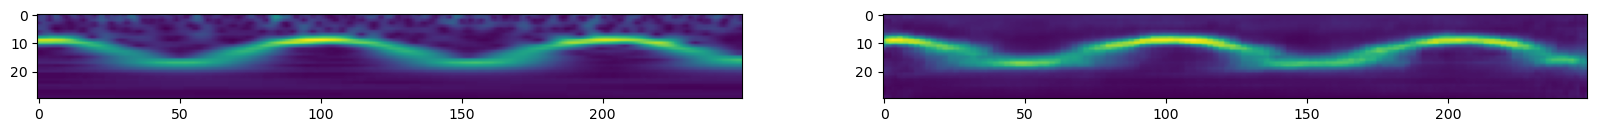

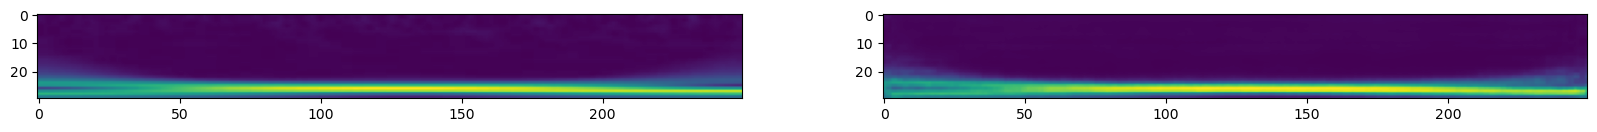

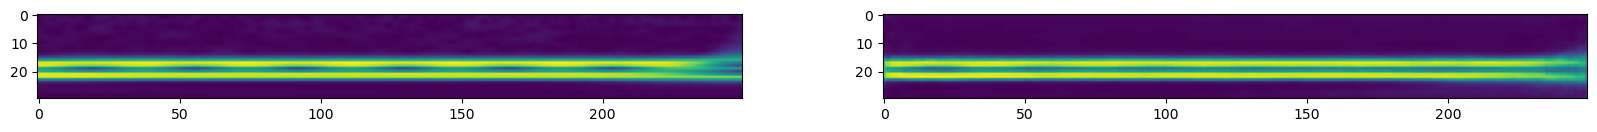

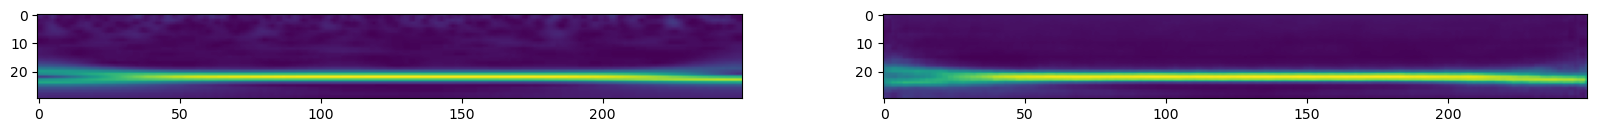

In [28]:
x, _ = next(iter(train_dl))
trapallada.plot.img_and_pred(model, x[0], dim_z)
trapallada.plot.img_and_pred(model, x[1], dim_z)
trapallada.plot.img_and_pred(model, x[3], dim_z)
trapallada.plot.img_and_pred(model, x[15], dim_z)

## Latent space

For the sake of convenience

In [29]:
encoder, decoder = model

The `encoder` yields the mean and standard deviation

In [30]:
encoder(x[0].numpy())

Array([0.32375142, 0.49253845, 0.20377871, 0.00221189, 0.00277637,
       0.00373616], dtype=float32)

The `z` and label of every element in the training set (computed batch-wise due to memory problems)

In [31]:
z_s, labels, sds = [], [], []
for x, (l, sd) in train_dl:
    z_s.append(jax.vmap(encoder)(x.numpy()))
    labels.append(l)
    sds.append(sd)

All the values are (vertically) stacked together, and the standard deviation of `z` is dropped

In [32]:
z_s = jnp.vstack(z_s)[:, :dim_z]
labels = torch.concat(labels)
sds = torch.concat(sds)
z_s.shape, labels.shape, sds.shape

((14400, 3), torch.Size([14400]), torch.Size([14400]))

t-SNE

In [33]:
t_sne_embeddings = TSNE(n_components=2, perplexity=30,random_state=42).fit_transform(z_s)

It'll be used a couple of times

In [34]:
z_s_names = [f'z_{i}' for i in range(1, 1+dim_z)]
z_s_names

['z_1', 'z_2', 'z_3']

In [35]:
df = pd.DataFrame(np.hstack((z_s, t_sne_embeddings)), columns=z_s_names + ['tsne_1', 'tsne_2'])
df['label'] = [dict(ds.labels_names)[e] for e in labels.tolist()]
df['label'] = df['label'].astype('category')
df['std'] = sds
df['file name'] = ds.labels_df['file name']
df

,z_1,z_2,z_3,tsne_1,tsne_2,label,std,file name
0,-0.141385,0.506058,-1.724459,-24.419725,13.542449,Constant,10.0,Constant/cLC_s1_793.jpg
1,-6.437694,-0.553013,5.450684,96.819557,38.682877,FM,2.0,Constant/cLC_s3_524.jpg
2,-0.956400,0.548409,1.842207,47.208263,31.021147,FM,3.0,Constant/cLC_s3_956.jpg
3,-0.209767,1.880317,-4.540688,-51.433483,25.842186,AM,1.0,Constant/cLC_s3_283.jpg
4,-2.134644,3.275158,0.785040,-25.496674,91.494827,FM,3.0,Constant/cLC_s5_666.jpg
...,...,...,...,...,...,...,...,...
14395,0.530258,-1.189120,1.568644,68.483803,-58.285801,Constant,5.0,AM/AM_s10_461.jpg
14396,3.778467,2.685337,-0.687505,-98.348167,-9.436743,AM,3.0,AM/AM_s4_495.jpg
14397,2.211899,-1.046972,0.564510,-11.589099,-69.961708,Constant,1.0,AM/AM_s10_71.jpg
14398,-1.984468,1.094917,-1.842858,-25.512142,47.436192,AM,1.0,AM/AM_s4_332.jpg


In [36]:
alt.Chart(df.sample(n=1_000)).mark_point().encode(
    x='tsne_1:Q',
    y='tsne_2:Q',
    color='label:N',
    fill='label:N',
    size='std:Q',
    tooltip=['file name:N']
).properties(
    width=800, height=600
).interactive()

alt.Chart(...)

In [40]:
# fig = px.scatter_3d(df, x='z_1', y='z_2', z='z_3', color='label', size='std')
fig = px.scatter_3d(df, x='z_1', y='z_2', z='z_3', color='label', opacity=0.5)
# fig = px.scatter_3d(df.assign(std=lambda x: np.log(x['std']) + 0.1), x='z_1', y='z_2', z='z_3', color='label', size='std')
# fig.show(renderer='iframe')
fig.show()
# fig.write_image(weights_filename.with_suffix('.pdf'))

In [71]:
files = ['FM_s3_322.jpg', 'AM_s4_420.jpg']
# files = ['FM_s10_304.jpg', 'AM_s1_298.jpg']
# files = ['FM_s10_371', 'cLC_s2_639']
# files_df = df[df['file name'].isin(files)]
files_df = df[df['file name'].str.contains('|'.join(files), regex=True)]
print(f'distance {jnp.linalg.norm(jnp.subtract(*files_df[z_s_names].values)).item()}')
files_df

distance 0.8983180522918701


,z_1,z_2,z_3,tsne_1,tsne_2,label,std,file name
9747,-0.449094,1.013403,1.694189,31.886049,33.822811,AM,10.0,FM/FM_s3_322.jpg
13932,-0.659336,1.835848,1.988055,24.579542,21.225136,FM,10.0,AM/AM_s4_420.jpg


In [60]:
# # t_sne_embeddings[files_df.index.values]
# files_z_s = z_s[files_df.index.values]
# print(f'distance {jnp.linalg.norm(jnp.subtract(*files_z_s)).item()}')
# files_z_s

distance 0.8983180522918701


Array([[-0.44909397,  1.0134027 ,  1.6941893 ],
       [-0.65933585,  1.8358481 ,  1.9880555 ]], dtype=float32)

In [125]:
images_basedir = pathlib.Path.cwd() / 'Simulations'
assert images_basedir.exists()

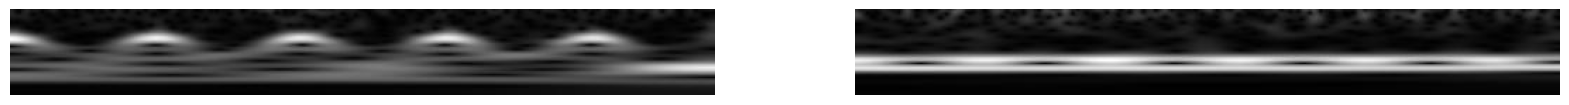

In [126]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for i_f, f in enumerate(files_df['file name']):
    image = mpimg.imread(images_basedir / f)
    axes[i_f].imshow(image)
    axes[i_f].axis('off')

In [129]:
output_file = f'analysis_{"-".join(files)}.jpg'
fig.savefig(output_file, bbox_inches='tight')

In [130]:
# from IPython.display import display, Markdown
# display(Markdown(f"[Open Saved Plot]({output_file})"))

In [131]:
from IPython.display import HTML
download_link = f'<a href="{output_file}" download>Download Saved Plot</a>'
HTML(download_link)

In [74]:
pd.read_parquet(parameters_filename.with_suffix('.parquet'))

train                                     valid                 \
              loss log_likelihood            KL         loss log_likelihood   
0     5.263407e+06  -5.252146e+06  11260.746680  5731.315386   -5713.033843   
1     2.220971e+06  -2.215758e+06   5213.066675  4558.033287   -4545.509891   
2     2.001894e+06  -1.996676e+06   5218.362113  4377.781611   -4367.748719   
3     1.949016e+06  -1.945007e+06   4009.270046  4304.290553   -4296.050684   
4     1.923711e+06  -1.920293e+06   3418.557996  4251.083263   -4243.135584   
...            ...            ...           ...          ...            ...   
4995 -4.493344e+05   4.577826e+05   8448.190651  -718.941410     737.741113   
4996 -4.493111e+05   4.577688e+05   8457.633696  -724.834956     743.550653   
4997 -4.492175e+05   4.576564e+05   8438.941839  -728.834212     747.520473   
4998 -4.491836e+05   4.576253e+05   8441.729927  -728.250990     747.035365   
4999 -4.492446e+05   4.576902e+05   8445.601343  -722.821855     741.569960   

                 
             KL  
0     18.281553  
1     12.523397  
2     10.032901  
3      8.239877  
4      7.947688  
...         ...  
4995  18.799705  
4996  18.715698  
4997  18.686260  
4998  18.784372  
4999  18.748107  

[5000 rows x 6 columns]